# K-Nearest Neighbors & Timeseries Forecasting

In [1]:
!pip -q install yfinance holidays


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

---
# Μέρος 1 – KNN

## Ερώτημα 1

> Φορτώστε το αρχείο airline_passenger_satisfaction.csv. Για τις αριθμητικές τιμές, εμφανίστε το ιστόγραμμα (histogram)
> με την κατανομή. Για τις κατηγορικές τιμές εμφανίστε ένα ραβδόγραμμα με το πλήθος εμφάνισης των κατηγοριών. Τέλος, να
> αναφέρετε αν κάποια κλάση υπερισχύει της άλλης (μη ισορροπημένες κλάσεις)

In [3]:
import os
if not os.path.exists("airline_passenger_satisfaction.csv"):
    from google.colab import files
    files.upload()   # επιλέξτε τα airline_passenger_satisfaction.csv και airlines_data_dictionary.csv

df = pd.read_csv("airline_passenger_satisfaction.csv")
dictionary = pd.read_csv("airlines_data_dictionary.csv")
df.head()

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


In [4]:
dictionary

,Field,Description
0,ID,Unique passenger identifier
1,Gender,Gender of the passenger (Female/Male)
2,Age,Age of the passenger
3,Customer Type,Type of airline customer (First-time/Returning)
4,Type of Travel,Purpose of the flight (Business/Personal)
5,Class,Travel class in the airplane for the passenger...
6,Flight Distance,Flight distance in miles
7,Departure Delay,Flight departure delay in minutes
8,Arrival Delay,Flight arrival delay in minutes
9,Departure and Arrival Time Convenience,Satisfaction level with the convenience of the...


Αριθμητικές μεταβλητές είναι οι Age, Flight Distance, Departure Delay και Arrival Delay. Οι υπόλοιπες είναι κατηγορικές. Η ID δεν χρησιμοποιείται.

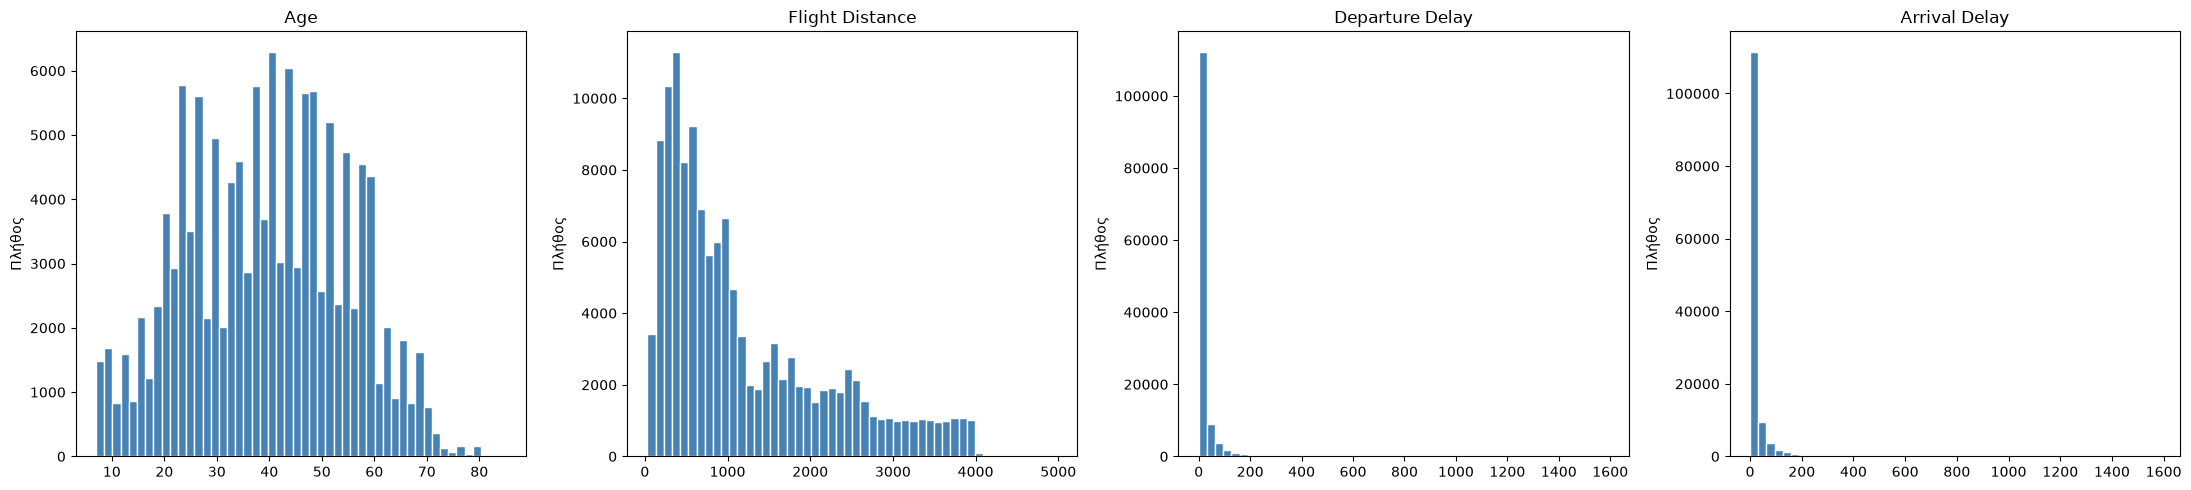

In [5]:
numeric_cols = ["Age", "Flight Distance", "Departure Delay", "Arrival Delay"]
nominal_cols = ["Gender", "Customer Type", "Type of Travel"]
target_col = "Satisfaction"
rating_cols = [c for c in df.columns if c not in numeric_cols + nominal_cols + ["Class", target_col, "ID"]]
categorical_cols = nominal_cols + ["Class"] + rating_cols + [target_col]

# Ιστογράμματα αριθμητικών μεταβλητών
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, col in zip(axes, numeric_cols):
    ax.hist(df[col].dropna(), bins=50, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Πλήθος")
plt.tight_layout()
plt.show()

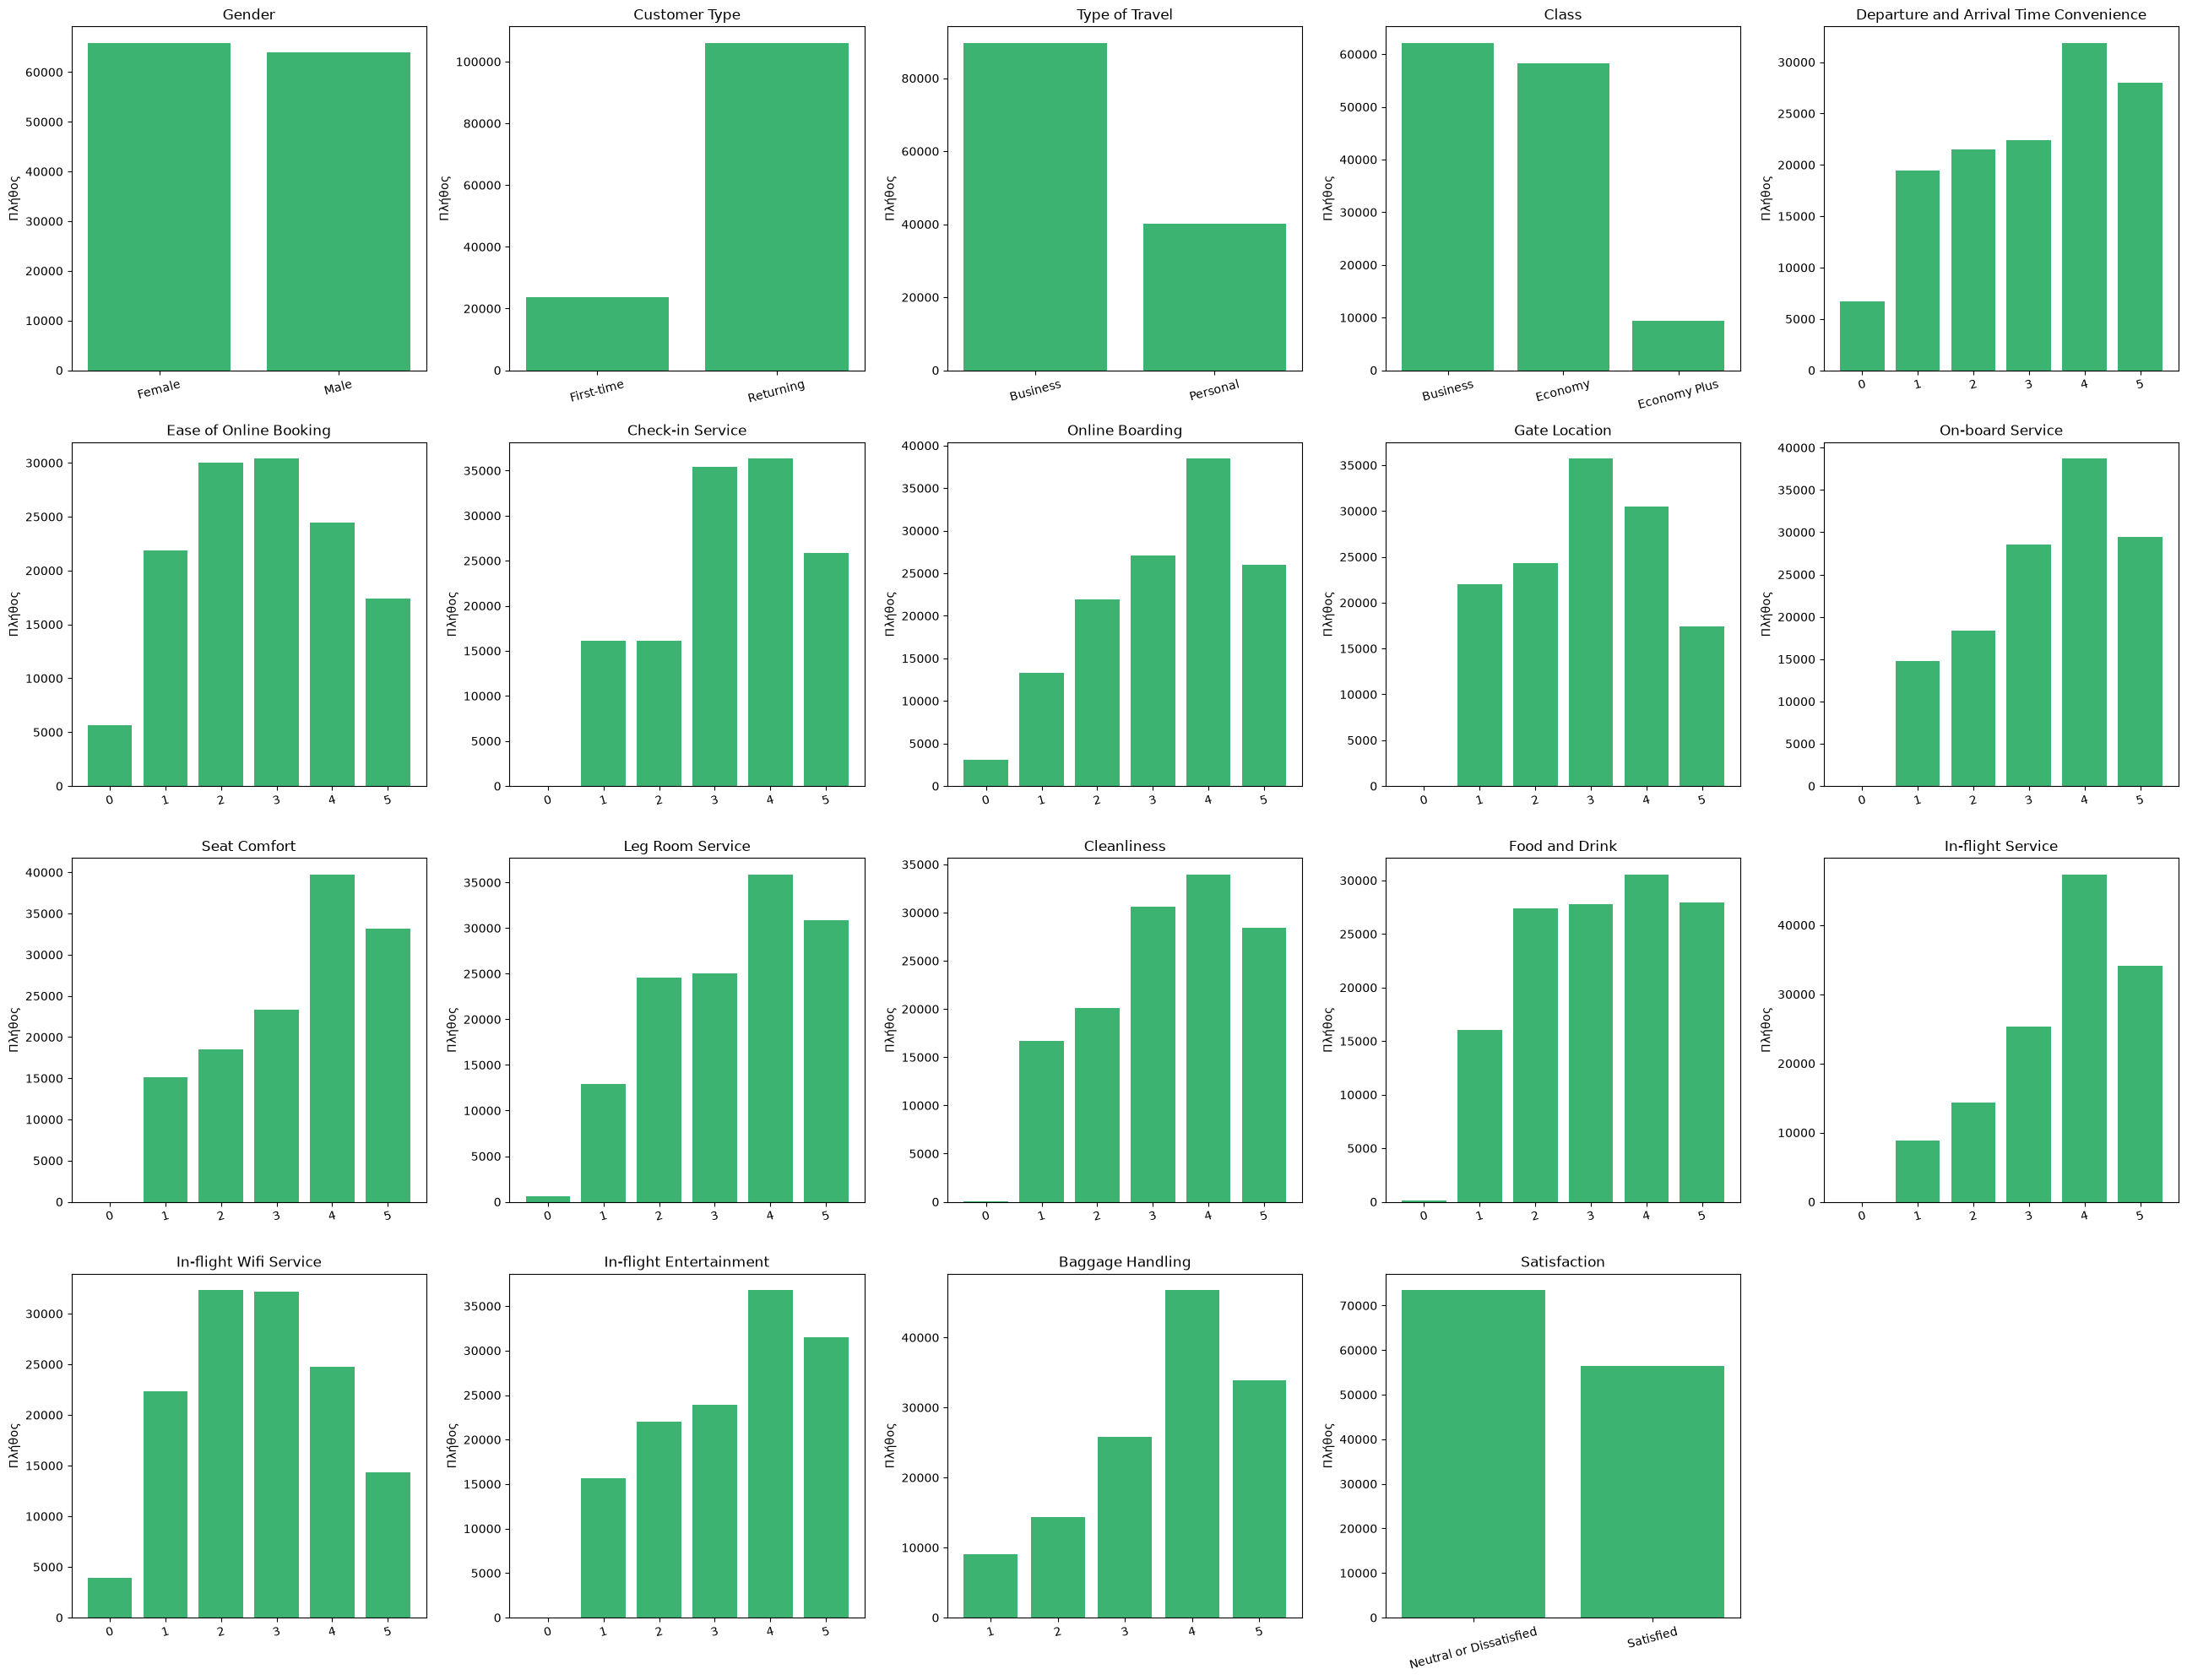

In [6]:
# Ραβδογράμματα κατηγορικών μεταβλητών
fig, axes = plt.subplots(4, 5, figsize=(26, 20))
axes = axes.ravel()
for ax, col in zip(axes, categorical_cols):
    counts = df[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color="mediumseagreen")
    ax.set_title(col)
    ax.set_ylabel("Πλήθος")
    ax.tick_params(axis="x", rotation=15)
for ax in axes[len(categorical_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [7]:
pd.DataFrame({"Πλήθος": df[target_col].value_counts(),
              "Ποσοστό (%)": (df[target_col].value_counts(normalize=True) * 100).round(2)})

,Πλήθος,Ποσοστό (%)
Satisfaction,,
Neutral or Dissatisfied,73452,56.55
Satisfied,56428,43.45


Η κλάση Neutral or Dissatisfied (56,55%) υπερισχύει ελαφρώς της Satisfied (43,45%).

## Ερώτημα 2

> Εφαρμόστε κατάλληλη τεχνική κωδικοποίησης στις κατηγορικές μεταβλητές. Κάποιες μεταβλητές μπορούν να κωδικοποιηθούν με
> παραπάνω από έναν τρόπο.

Οι ονομαστικές μεταβλητές Gender, Customer Type και Type of Travel κωδικοποιούνται με one-hot. Η Class είναι διατάξιμη και κωδικοποιείται με ordinal (Economy=0, Economy Plus=1, Business=2), αλλά μπορεί να κωδικοποιηθεί και με one-hot. Οι βαθμολογίες 0–5 είναι ήδη διατάξιμες αριθμητικές τιμές. Οι 393 γραμμές με κενό Arrival Delay αφαιρούνται.

In [8]:
print("Κενές τιμές:\n", df.isna().sum()[df.isna().sum() > 0])
data = df.drop(columns=["ID"]).dropna()

# Ονομαστικές -> one-hot
data = pd.get_dummies(data, columns=nominal_cols, dtype=int)

# Class: τρόπος 1 -> ordinal
data_ordinal = data.copy()
data_ordinal["Class"] = data_ordinal["Class"].map({"Economy": 0, "Economy Plus": 1, "Business": 2})

# Class: τρόπος 2 -> one-hot
data_onehot = pd.get_dummies(data, columns=["Class"], dtype=int)

# Κλάση
data_ordinal[target_col] = data_ordinal[target_col].map({"Neutral or Dissatisfied": 0, "Satisfied": 1})
data_onehot[target_col] = data_onehot[target_col].map({"Neutral or Dissatisfied": 0, "Satisfied": 1})

data_onehot.head()

Κενές τιμές:
 Arrival Delay    393
dtype: int64


,Age,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,...,Satisfaction,Gender_Female,Gender_Male,Customer Type_First-time,Customer Type_Returning,Type of Travel_Business,Type of Travel_Personal,Class_Business,Class_Economy,Class_Economy Plus
0,48,821,2,5.0,3,3,4,3,3,3,...,0,0,1,1,0,1,0,1,0,0
1,35,821,26,39.0,2,2,3,5,2,5,...,1,1,0,0,1,1,0,1,0,0
2,41,853,0,0.0,4,4,4,5,4,3,...,1,0,1,0,1,1,0,1,0,0
3,50,1905,0,0.0,2,2,3,4,2,5,...,1,0,1,0,1,1,0,1,0,0
4,49,3470,0,1.0,3,3,3,5,3,3,...,1,1,0,0,1,1,0,1,0,0


In [9]:
# Για τον KNN χρησιμοποιούμε την ordinal κωδικοποίηση της Class (διατηρεί τη διάταξη των θέσεων)
encoded = data_ordinal
feature_cols = [c for c in encoded.columns if c != target_col]
encoded.head()

,Age,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,...,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction,Gender_Female,Gender_Male,Customer Type_First-time,Customer Type_Returning,Type of Travel_Business,Type of Travel_Personal
0,48,2,821,2,5.0,3,3,4,3,3,...,3,5,5,0,0,1,1,0,1,0
1,35,2,821,26,39.0,2,2,3,5,2,...,2,5,5,1,1,0,0,1,1,0
2,41,2,853,0,0.0,4,4,4,5,4,...,4,3,3,1,0,1,0,1,1,0
3,50,2,1905,0,0.0,2,2,3,4,2,...,2,5,5,1,0,1,0,1,1,0
4,49,2,3470,0,1.0,3,3,3,5,3,...,3,3,3,1,1,0,0,1,1,0


## Ερώτημα 3

> Δημιουργήστε Numpy arrays και χωρίστε το σύνολο εκπαίδευσης σε 70-30% train test χρησιμοποιώντας τη μέθοδο
> train_test_split με seed=0 (random_state=0).

In [10]:
from sklearn.model_selection import train_test_split

X = encoded[feature_cols].to_numpy(dtype=float)
y = encoded[target_col].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (90640, 25) X_test: (38847, 25)


## Ερώτημα 4

> Εφαρμόστε κατάλληλη κανονικοποίηση στις μεταβλητές (μόνο στις αριθμητικές)!! Αιτιολογήστε το λόγο.

Ο KNN υπολογίζει αποστάσεις, οπότε μεταβλητές με μεγάλο εύρος τιμών, όπως το Flight Distance (έως ~5000), θα κυριαρχούσαν έναντι των υπολοίπων. Χρησιμοποιούμε Z-Score και όχι Min-Max, γιατί οι καθυστερήσεις έχουν ακραίες τιμές.

In [11]:
from sklearn.preprocessing import StandardScaler

num_idx = [feature_cols.index(c) for c in numeric_cols]

scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[:, num_idx] = scaler.fit_transform(X_train[:, num_idx])
X_test_s[:, num_idx] = scaler.transform(X_test[:, num_idx])

## Ερώτημα 5

> Προσαρμόστε ταξινομητή KNN με Ευκλείδεια απόσταση. Σε μία for loop, δοκιμάστε 12 συνδυασμούς του k (k=3,5,15,51, 151,
> N) όπου N το πλήθος των παραδειγμάτων, μαζί με την επιλογή βαρών γειτόνων uniform-distance KNN. Να κατασκευάσετε
> πινακάκι με την ακρίβεια στο Train-Test κάθε συνδυασμού και να αναφέρετε τον καλύτερο συνδυασμό.

Για k=N το KNeighborsClassifier δεν χωράει στη μνήμη, οπότε η ψηφοφορία όλων των παραδειγμάτων υπολογίζεται με τη συνάρτηση `knn_k_equals_N`.

In [12]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

def knn_k_equals_N(X_ref, y_ref, X_query, weights, batch=500):
    classes = np.unique(y_ref)
    if weights == "uniform":
        majority = classes[np.argmax([(y_ref == c).sum() for c in classes])]
        return np.full(len(X_query), majority)
    onehot = (y_ref[:, None] == classes[None, :]).astype(float)
    ref_sq = (X_ref ** 2).sum(axis=1)
    preds = np.empty(len(X_query), dtype=y_ref.dtype)
    for s in range(0, len(X_query), batch):
        q = X_query[s:s + batch]
        d = np.sqrt(np.maximum((q ** 2).sum(axis=1)[:, None] + ref_sq[None, :] - 2 * q @ X_ref.T, 0))
        zero = d < 1e-6
        with np.errstate(divide="ignore"):
            w = np.where(zero.any(axis=1)[:, None], zero.astype(float), 1.0 / d)   # dist = 0: μετράει μόνο αυτός ο γείτονας
        preds[s:s + batch] = classes[np.argmax(w @ onehot, axis=1)]
    return preds

N = X_train_s.shape[0]
results = []
for k in [3, 5, 15, 51, 151, N]:
    for w in ["uniform", "distance"]:
        if k < N:
            knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric="euclidean", n_jobs=-1)
            knn.fit(X_train_s, y_train)
            train_acc = knn.score(X_train_s, y_train)
            test_acc = knn.score(X_test_s, y_test)
        else:
            train_acc = accuracy_score(y_train, knn_k_equals_N(X_train_s, y_train, X_train_s, w))
            test_acc = accuracy_score(y_test, knn_k_equals_N(X_train_s, y_train, X_test_s, w))
        results.append({"k": f"N={N}" if k == N else k, "weights": w,
                        "Train Accuracy": round(train_acc, 4), "Test Accuracy": round(test_acc, 4)})

results_df = pd.DataFrame(results)
results_df

,k,weights,Train Accuracy,Test Accuracy
0,3,uniform,0.9603,0.9289
1,3,distance,1.0000,0.9289
2,5,uniform,0.9508,0.9313
3,5,distance,1.0000,0.9312
4,15,uniform,0.9373,0.9315
5,15,distance,1.0000,0.9319
6,51,uniform,0.9269,0.9249
7,51,distance,1.0000,0.9259
8,151,uniform,0.9168,0.9149
9,151,distance,1.0000,0.9168


In [13]:
best = results_df.loc[results_df["Test Accuracy"].idxmax()]
print(f"Καλύτερος συνδυασμός: k={best['k']}, weights={best['weights']}, Test Accuracy={best['Test Accuracy']}")

Καλύτερος συνδυασμός: k=15, weights=distance, Test Accuracy=0.9319


Ο καλύτερος συνδυασμός είναι k=15 με weights=distance (Test Accuracy 0,9319). Με distance η ακρίβεια στο train είναι πάντα 1, γιατί κάθε παράδειγμα είναι γείτονας του εαυτού του.

---
# Μέρος 2 – Πρόβλεψη Χρονοσειρών

Για την τιμή του δολαρίου χρησιμοποιείται ο δείκτης `DX-Y.NYB`.

In [14]:
import yfinance as yf

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    usd = yf.Ticker("DX-Y.NYB").history(period="10y")
usd = usd.drop(columns=["Volume", "Dividends", "Stock Splits"])
usd.index = usd.index.tz_localize(None).normalize()
usd.head()

,Open,High,Low,Close
Date,,,,
2016-10-31,98.320000,98.699997,98.290001,98.449997
2016-11-01,98.389999,98.480003,97.639999,97.699997
2016-11-02,97.750000,97.800003,97.180000,97.400002
2016-11-03,97.379997,97.459999,97.040001,97.160004
2016-11-04,97.160004,97.349998,96.889999,97.070000


## Ερώτημα 1

> Εξηγήστε τις μεταβλητές OHLCV και περιγράψτε μέση τιμή, τυπική απόκλιση. Να δημιουργηθεί ένα μόνο πολύγωνο (line plot)
> με άξονα y την τιμή κάθε μεταβλητής High, Low, Close και άξονα x την ημερομηνία. Χρησιμοποιείστε τη βιβλιοθήκη Plotly.
> Μεγαλώστε το γράφημα (να ναι ευκρινές).

Open είναι η τιμή εκκίνησης της ημέρας, High η υψηλότερη και Low η χαμηλότερη τιμή μέσα στη μέρα, Close η τιμή κλεισίματος και Volume ο όγκος συναλλαγών.

In [15]:
usd.agg(["mean", "std"])

,Open,High,Low,Close
mean,98.799560,99.100405,98.509801,98.809633
std,4.971375,5.018982,4.915228,4.972942


Η μέση τιμή όλων των μεταβλητών είναι περίπου 98,8 και η τυπική απόκλιση περίπου 5.

In [16]:
fig = go.Figure()
for col in ["High", "Low", "Close"]:
    fig.add_trace(go.Scatter(x=usd.index, y=usd[col], mode="lines", name=col))
fig.update_layout(title="USD (DX-Y.NYB): High, Low, Close", xaxis_title="Ημερομηνία", yaxis_title="Τιμή",
                  width=1400, height=700)
fig.show()

## Ερώτημα 2

> Από το πολύγωνο του ερωτήματος (1), παρατηρείτε πως είναι στάσιμες ή μη στάσιμες οι χρονοσειρές? Αιτιολογήστε.

Οι χρονοσειρές είναι μη στάσιμες, γιατί έχουν τάσεις και η μέση τιμή τους αλλάζει στον χρόνο.

## Ερώτημα 3

> Να τρέξετε στατιστικά test ADF και KPSS για να επαληθεύσετε το ερώτημα 2.

In [17]:
from statsmodels.tsa.stattools import adfuller, kpss

def interpret(adf_p, kpss_p):
    if adf_p < 0.05 and kpss_p >= 0.05: return "Ένδειξη στασιμότητας"
    if adf_p >= 0.05 and kpss_p < 0.05: return "Ένδειξη μη στασιμότητας"
    if adf_p < 0.05 and kpss_p < 0.05:  return "Αντικρουόμενα αποτελέσματα"
    return "Ασαφές αποτέλεσμα"

rows = []
for col in usd.columns:
    adf_p = adfuller(usd[col])[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_p = kpss(usd[col], nlags="auto")[1]
    rows.append({"Μεταβλητή": col, "ADF p-value": round(adf_p, 4), "KPSS p-value": round(kpss_p, 4),
                 "Ερμηνεία": interpret(adf_p, kpss_p)})
pd.DataFrame(rows)

,Μεταβλητή,ADF p-value,KPSS p-value,Ερμηνεία
0,Open,0.3426,0.01,Ένδειξη μη στασιμότητας
1,High,0.3374,0.01,Ένδειξη μη στασιμότητας
2,Low,0.2959,0.01,Ένδειξη μη στασιμότητας
3,Close,0.3381,0.01,Ένδειξη μη στασιμότητας


Σε όλες τις μεταβλητές ADF p-value ≥ 0,05 και KPSS p-value < 0,05, άρα οι χρονοσειρές είναι μη στάσιμες, όπως στο Ερώτημα 2.

## Ερώτημα 4

> Χωρίστε τα DataFrames σε train-test sets (70-30%).

Ο διαχωρισμός γίνεται με χρονική σειρά, χωρίς ανακάτεμα.

In [18]:
n = len(usd)
n_train = int(n * 0.7)
train_df = usd.iloc[:n_train]
test_df = usd.iloc[n_train:]
print("Train:", train_df.shape, train_df.index.min().date(), "-", train_df.index.max().date())
print("Test :", test_df.shape, test_df.index.min().date(), "-", test_df.index.max().date())

Train: (1759, 4) 2016-10-31 - 2023-10-27
Test : (755, 4) 2023-10-30 - 2026-10-29


## Ερώτημα 5

> Εκπαιδεύστε μοντέλο Linear Regression να προβλέπει τη τιμή κλεισίματος της επόμενης ημέρας Close(t+1) και αξιολογείστε
> το στα Train-Test με κατάλληλη μετρική. Δοκιμάστε την απόδοση του μοντέλου για timeframes μεγέθους H=[1,5,15,30] και
> κατασκευάστε ραβδόγραμμα με τα αποτελέσματα.

Κάθε είσοδος είναι οι τιμές Open, High, Low, Close των τελευταίων H ημερών σε ένα διάνυσμα (flatten), και ο στόχος είναι το Close(t+1). Ως μετρική χρησιμοποιείται το MAE.

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

H_LIST = [1, 5, 15, 30]
START = max(H_LIST) + 1
train_idx = np.arange(START, n_train)      # θέσεις-στόχοι Close(t+1) στο train
test_idx = np.arange(n_train, n)           # θέσεις-στόχοι Close(t+1) στο test
price_cols = ["Open", "High", "Low", "Close"]
close = usd["Close"].to_numpy()

def make_timeframes(features, target, H, idx, future=None):
    # X = flatten(features[t-H+1 .. t]) (+ γνωστά μελλοντικά χαρακτηριστικά της t+1), y = target[t+1]
    F = np.asarray(features, dtype=float)
    X = np.stack([F[j - H:j].ravel() for j in idx])
    if future is not None:
        X = np.hstack([X, np.asarray(future, dtype=float)[idx]])
    return X, np.asarray(target, dtype=float)[idx]

def run_model(H, features, future=None):
    X_tr, y_tr = make_timeframes(features, close, H, train_idx, future)
    X_te, y_te = make_timeframes(features, close, H, test_idx, future)
    model = LinearRegression().fit(X_tr, y_tr)
    return model.predict(X_tr), model.predict(X_te)

rows, preds = [], {}
for H in H_LIST:
    p_tr, p_te = run_model(H, usd[price_cols])
    preds[H] = (p_tr, p_te)
    rows.append({"H": H, "Train MAE": mean_absolute_error(close[train_idx], p_tr),
                 "Test MAE": mean_absolute_error(close[test_idx], p_te)})
res_abs = pd.DataFrame(rows).set_index("H")
res_abs.round(4)

,Train MAE,Test MAE
H,,
1,0.3084,0.3094
5,0.3080,0.3076
15,0.3036,0.3162
30,0.2995,0.3239


In [20]:
def bar_mae(res, title):
    fig = go.Figure()
    for col in ["Train MAE", "Test MAE"]:
        fig.add_trace(go.Bar(x=[f"H={h}" for h in res.index], y=res[col], name=col,
                             text=res[col].round(4), textposition="outside"))
    fig.update_layout(title=title, barmode="group", yaxis_title="MAE", width=1000, height=500)
    fig.show()

bar_mae(res_abs, "Linear Regression: MAE ανά timeframe H")

Το καλύτερο Test MAE είναι για H=5. Όσο μεγαλώνει το H, το Train MAE μειώνεται αλλά το Test MAE αυξάνεται, γιατί οι παλαιότερες τιμές προσθέτουν θόρυβο.

## Ερώτημα 6

> Για H=30 κατασκευάστε πολύγωνο με τις προβλέψεις του μοντέλου στα train και test, καθώς και τις αντίστοιχες πραγματικές
> τιμές. Μπορείτε να τα σχεδιάσετε τα πολύγωνα στο ίδιο plot. Για το train set, να εμφανίσετε το πολύγωνο μόνο για τις
> τελευταίες 30 Close τιμές. Τι παρατηρείτε για τις προβλεπόμενες τιμές σε σχέσεις με τις πραγματικές;

In [21]:
def plot_predictions(p_tr, p_te, title, last_n=30):
    d_tr, d_te = usd.index[train_idx][-last_n:], usd.index[test_idx]
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=d_tr, y=close[train_idx][-last_n:], mode="lines+markers", name="Train – πραγματικές"))
    fig.add_trace(go.Scatter(x=d_tr, y=p_tr[-last_n:], mode="lines+markers", name="Train – προβλέψεις",
                             line=dict(dash="dash")))
    fig.add_trace(go.Scatter(x=d_te, y=close[test_idx], mode="lines", name="Test – πραγματικές"))
    fig.add_trace(go.Scatter(x=d_te, y=p_te, mode="lines", name="Test – προβλέψεις", line=dict(dash="dash")))
    fig.update_layout(title=title, xaxis_title="Ημερομηνία", yaxis_title="Close", width=1400, height=650)
    fig.show()

plot_predictions(*preds[30], "H=30: προβλέψεις και πραγματικές τιμές Close")

Οι προβλέψεις ακολουθούν τις πραγματικές τιμές με καθυστέρηση μίας ημέρας, δηλαδή η πρόβλεψη για αύριο είναι σχεδόν η σημερινή τιμή.

## Ερώτημα 7

> Εφαρμόστε το μετασχηματισμό Log-Returns στα δεδομένα και επαναλάβετε το ερώτημα 5. Για την αξιολόγηση, μετατρέψτε τα
> δεδομένα σε απόλυτες τιμές και συγκρίνεται την απόδοση των μοντέλων του ερωτήματος 5.

Το μοντέλο προβλέπει το $lr_{t+1} = \ln(y_{t+1}/y_t)$ και η πρόβλεψη μετατρέπεται σε απόλυτη τιμή με $\hat{y}_{t+1} = y_t \cdot e^{\widehat{lr}_{t+1}}$.

In [22]:
log_ret = np.log(usd[price_cols] / usd[price_cols].shift(1))
lr_close = log_ret["Close"].to_numpy()

def run_logret_model(H, features, future=None):
    X_tr, y_tr = make_timeframes(features, lr_close, H, train_idx, future)
    X_te, y_te = make_timeframes(features, lr_close, H, test_idx, future)
    model = LinearRegression().fit(X_tr, y_tr)
    # Μετατροπή σε απόλυτες τιμές: Close(t+1) = Close(t) * e^{lr(t+1)}
    return close[train_idx - 1] * np.exp(model.predict(X_tr)), close[test_idx - 1] * np.exp(model.predict(X_te))

rows = []
for H in H_LIST:
    p_tr, p_te = run_logret_model(H, log_ret)
    rows.append({"H": H, "Train MAE": mean_absolute_error(close[train_idx], p_tr),
                 "Test MAE": mean_absolute_error(close[test_idx], p_te)})
res_lr = pd.DataFrame(rows).set_index("H")
res_lr.round(4)

,Train MAE,Test MAE
H,,
1,0.3080,0.3083
5,0.3070,0.3077
15,0.3032,0.3151
30,0.2988,0.3224


In [23]:
bar_mae(res_lr, "Linear Regression με Log-Returns (σε απόλυτες τιμές): MAE ανά timeframe H")

comparison = pd.DataFrame({"Test MAE – Ερώτημα 5 (απόλυτες τιμές)": res_abs["Test MAE"],
                           "Test MAE – Ερώτημα 7 (log-returns)": res_lr["Test MAE"]})
comparison.round(4)

,Test MAE – Ερώτημα 5 (απόλυτες τιμές),Test MAE – Ερώτημα 7 (log-returns)
H,,
1,0.3094,0.3083
5,0.3076,0.3077
15,0.3162,0.3151
30,0.3239,0.3224


Με log-returns το Test MAE είναι λίγο μικρότερο για H=1, 15, 30 και σχεδόν ίσο για H=5, γιατί τα log-returns είναι στάσιμα και προβλέπονται ευκολότερα.

## Ερώτημα 8

> Χρησιμοποιήστε το Granger Causality Tests για να ελέγξετε αν η μεταβλητή Open είναι χρήσιμη για την πρόβλεψη του
> Close, καθώς και ποια χρονικά βήματα είναι σημαντικά.

Το test εφαρμόζεται στα log-returns, που είναι στάσιμα. Ένα lag είναι σημαντικό όταν p-value < 0,05.

In [24]:
from statsmodels.tsa.stattools import grangercausalitytests
import io, contextlib

with contextlib.redirect_stdout(io.StringIO()):
    gc = grangercausalitytests(log_ret[["Close", "Open"]].dropna(), maxlag=15)

gc_table = pd.DataFrame({"lag": lag, "p-value": round(gc[lag][0]["ssr_ftest"][1], 4),
                         "Σημαντικό (p < 0.05)": "Ναι" if gc[lag][0]["ssr_ftest"][1] < 0.05 else "Όχι"}
                        for lag in range(1, 16)).set_index("lag")
gc_table

,p-value,Σημαντικό (p < 0.05)
lag,,
1,0.3783,Όχι
2,0.5082,Όχι
3,0.3529,Όχι
4,0.4958,Όχι
5,0.0025,Ναι
6,0.4861,Όχι
7,0.5503,Όχι
8,0.1977,Όχι
9,0.1465,Όχι


Μόνο το lag 5 είναι σημαντικό. Στα υπόλοιπα lags το Open δεν βοηθά στην πρόβλεψη του Close.

## Ερώτημα 9

> Προσθέστε επιπλέον χαρακτηριστικά, όπως ο δείκτης S&P500 (ticker='^GSPC'), καθώς και χρονικά χαρακτηριστικά (ημέρα
> εβδομάδας, μήνας). Επιπλέον, χρησιμοποιήστε τη βιβλιοθήκη holidays ώστε να συμπεριλάβετε μια δυαδική μεταβλητή
> 'Holiday', που ορίζεται ως {0: Όχι Γιορτή, 1: Γιορτή Αμερικής}. Έπειτα, για την κατασκευή των timeframes, να
> συμπεριλάβετε ως features και τα γνωστά μελλοντικά χαρακτηριστικά (ημέρα εβδομάδας, μήνα, γιορτή) και να επαναλάβετε το 6.

Η ημέρα εβδομάδας και ο μήνας κωδικοποιούνται με one-hot. Μαζί με το Holiday είναι γνωστά για την ημέρα t+1 και προστίθενται στο διάνυσμα εισόδου.

In [25]:
import holidays

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sp500 = yf.Ticker("^GSPC").history(period="10y")[["Close"]].rename(columns={"Close": "SP500"})
sp500.index = sp500.index.tz_localize(None).normalize()

feat = usd.join(sp500, how="left")
feat["SP500"] = feat["SP500"].ffill().bfill()     # ημέρες χωρίς τιμή S&P500: τελευταία γνωστή τιμή
feat["DayOfWeek"] = feat.index.dayofweek
feat["Month"] = feat.index.month
us_holidays = holidays.US(years=range(feat.index.year.min(), feat.index.year.max() + 1))
feat["Holiday"] = [1 if d in us_holidays else 0 for d in feat.index.date]
print("Ημέρες με Holiday = 1:", feat["Holiday"].sum())

# Γνωστά μελλοντικά χαρακτηριστικά της ημέρας t+1
future_cov = pd.concat([pd.get_dummies(feat["DayOfWeek"], prefix="DayOfWeek", dtype=int),
                        pd.get_dummies(feat["Month"], prefix="Month", dtype=int),
                        feat[["Holiday"]]], axis=1)
feat.head()

Ημέρες με Holiday = 1: 22


,Open,High,Low,Close,SP500,DayOfWeek,Month,Holiday
Date,,,,,,,,
2016-10-31,98.320000,98.699997,98.290001,98.449997,2126.149902,0,10,0
2016-11-01,98.389999,98.480003,97.639999,97.699997,2111.719971,1,11,0
2016-11-02,97.750000,97.800003,97.180000,97.400002,2097.939941,2,11,0
2016-11-03,97.379997,97.459999,97.040001,97.160004,2088.659912,3,11,0
2016-11-04,97.160004,97.349998,96.889999,97.070000,2085.179932,4,11,0


In [26]:
# Επανάληψη του Ερωτήματος 6 (H = 30) με τα επιπλέον χαρακτηριστικά
p_tr, p_te = run_model(30, feat[price_cols + ["SP500"]], future=future_cov)
print("H=30 Test MAE – Ερώτημα 6:", round(res_abs.loc[30, "Test MAE"], 4))
print("H=30 Test MAE – με επιπλέον χαρακτηριστικά:", round(mean_absolute_error(close[test_idx], p_te), 4))

plot_predictions(p_tr, p_te, "H=30 με S&P500, ημέρα εβδομάδας, μήνα, Holiday: προβλέψεις και πραγματικές τιμές Close")

H=30 Test MAE – Ερώτημα 6: 0.3239
H=30 Test MAE – με επιπλέον χαρακτηριστικά: 0.3383


Οι προβλέψεις ακολουθούν πάλι τις πραγματικές τιμές με καθυστέρηση μίας ημέρας. Τα επιπλέον χαρακτηριστικά δεν βελτίωσαν το μοντέλο, αφού το Test MAE αυξήθηκε από 0,324 σε 0,338.